In this notebook a naive approach for clustering one hit dataset is tried using Gaussian Mixture Models.

# 0 - General Set-Up

In this section general set up is done: import, dataset loading and processing.

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import ParameterGrid
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.pipeline import make_pipeline

import sys
from pathlib import Path

sys.path.append(str(Path("../../../src/utils").resolve()))
from dataset_balancing import balance_dataset

To ensure corretct reproduction: 

In [2]:
random_state = 42
np.random.seed(random_state)

In [3]:
file_path = "../../../data/Engineered_Datasets/"
file_name = "bgtgf_1hit_dataset.csv"

ds = pd.read_csv(file_path + file_name, header=0)
print(f"Dataset shape before balancing: {ds.shape}")
print(ds["particle_type"].value_counts())

n_samples = min(ds["particle_type"].value_counts().min(), 1000)
print(f"Balancing the dataset to have {n_samples} samples per class...")
ds = balance_dataset(ds, target_col="particle_type", n_samples = n_samples, random_state=random_state)
print(f"Dataset shape after balancing: {ds.shape}")

Dataset shape before balancing: (814681, 7)
particle_type
TGF                         578647
CosmicPhotons               137476
AlbedoPhotons                65628
SecondaryPositrons            6973
SecondaryProtonsUpward        5681
AtmosphericNeutrons           5661
SecondaryProtonsDownward      5232
SecondaryElectrons            3118
PrimaryProtons                2207
PrimaryPositrons              2147
PrimaryAlphas                 1035
PrimaryElectrons               876
Name: count, dtype: int64
Balancing the dataset to have 876 samples per class...
Dataset shape after balancing: (10512, 7)


## Data Pre-Processing

Dropping of meaningless feature is perfomed. Then convert data values to help clustering algorithm to properly work:
- Convert in log scale the Energy-based features in order to prevent unbalanced distance computation by clustering algorithm:
$log_{10}(x+1)$
- Apply `PowerTransformer(standardize=True)` to rescale to unit variance.



In [4]:
X = ds.drop(columns=["particle_type", "pixel_ijk", "com_z", "com_x", "com_y", "hits_sum"])
X.shape
y = ds["particle_type"]

In [5]:
log_cols = [c for c in X.columns if "E_" in c]
print(f"Columns to be log-transformed: {log_cols}")

for col in log_cols:
    X[col] = np.log10(X[col] + 1)

Columns to be log-transformed: ['E_sum']


In [6]:
preprocessor = make_pipeline(
    # StandardScaler(with_std=False),
    PowerTransformer(standardize=True),
)

X_transformed = pd.DataFrame(preprocessor.fit_transform(X), columns=X.columns)

Plot the difference of `E_sum` feature values after each pre-processing step:

Text(0.5, 1.0, 'Final E_sum (Standardized + Power Transformed)')

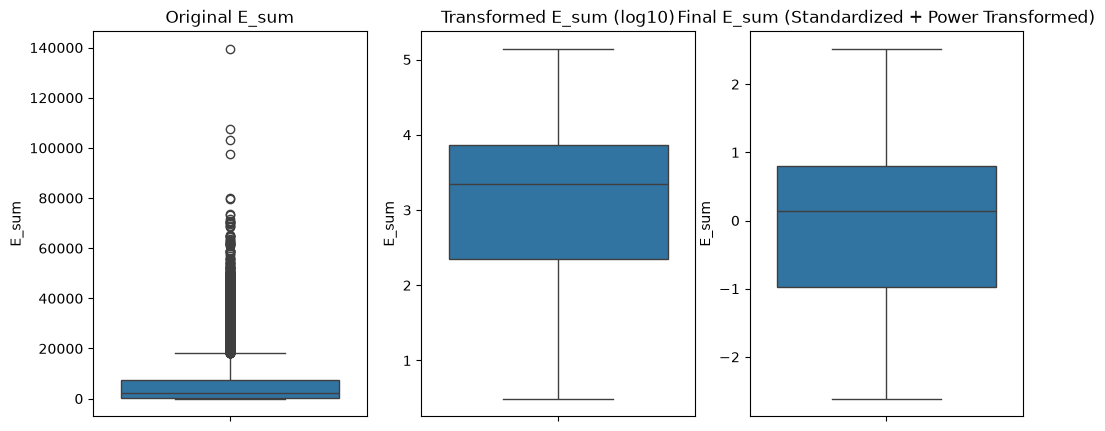

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
axes = axes.flatten()

feat = "E_sum"
sns.boxplot(data=ds[feat], ax=axes[0])
axes[0].set_title("Original E_sum")

sns.boxplot(data=X[feat], ax=axes[1])
axes[1].set_title("Transformed E_sum (log10)")

sns.boxplot(data=X_transformed[feat], ax=axes[2])
axes[2].set_title("Final E_sum (Standardized + Power Transformed)")

Recap of data in the dataset:

In [8]:
print(f"Shape of X_transformed: {X_transformed.shape}")
X_transformed.describe(include="all")

Shape of X_transformed: (10512, 1)


,E_sum
count,1.051200e+04
mean,-1.081496e-16
std,1.000048e+00
min,-2.612327e+00
25%,-9.712875e-01
50%,1.386943e-01
75%,7.932770e-01
max,2.521123e+00


# 1 - Gaussian Mixture Models (GMM)

A **Mixture Model** is a probabilistic model to represent the presence of subpopulation in a overall population. A Mixture Model corresponds to the mixture distribution which is the probability distribution in the overall population. 
A Gaussian mixture model (GMM) is a probabilistic model that assumes all the data are generated from a mixture of a finite number of Gaussian distributions with unknown parameters. Generalizing k-means clustering to incorporate information about the covariance structure of the data as well as the centers of the latent Gaussians (cit. Wikipedia Page and Scikit Learn page)
<br>
The GaussianMixture object implements the expectation-maximization (EM)  <span style="color:red">(TODO: spiegare cosa è)</span>. algorithm for fitting mixture-of-Gaussian models.
<br><br>
The metrics used are:
- **Normalized Mutual Information (NMI)**: Normalization of the Mutual Information score to a scale 0,1 where 0 is the *mutual information* and 1 is *perfect correlation*. The Mutual Information is a function that measures the agreement of the two assignments, ignoring permutations. 
- **Adjust Rand Index (ARI)**: Rand Index computes a similarity measure between two clusterings by considering all pairs of samples and counting pairs that are assigned in the same or different clusters in the predicted and true clusterings. The ARI gives a value close to 0 for random labeling independently of the number of clusters and samples and exactly 1 when the clusterings are identical (permutation is allowed).
- **Bayesian Information Criterion (BIC)**: criterion for model selection among a finite set of models, model with lower BIC are preferred. It's based in part on the likelihood function.   
- **Aikake Information Criterion (AIC)**: estimator of prediction error and relative quality of statistical models for a given set of data. Given a collection of models for the data, AIC estimates the quality of each model, relative to each of the other models.

When fitting models, it is possible to increase the maximum likelihood by adding parameters, but doing so may result in overfitting. Both BIC and AIC attempt to resolve this problem by introducing a penalty term for the number of parameters in the model; the penalty term is larger in BIC than in AIC for sample sizes greater than


In [9]:
k_range = range(2, 15)
params = {
    "n_components": [*k_range],
    # "n_components": [12],
    # "covariance_type": ["full", "tied", "diag", "spherical"],
    "covariance_type": ["full"],
    # "n_init": [5,10],
    "init_params": ['kmeans'],
    "random_state": [random_state]
}
pg = list(ParameterGrid(params))

In [10]:
gmm_df = pd.DataFrame(columns=["n_components", "silhouette", "bics", "aics", "NMI", "ARI"])

for k in range(len(pg)):
    gmm = GaussianMixture(**(pg[k]))
    ypred = gmm.fit_predict(X_transformed)

    gmm_df.loc[len(gmm_df)]=[
        
        pg[k]["n_components"],
        silhouette_score(X_transformed, ypred),
        gmm.bic(X_transformed),
        gmm.aic(X_transformed),
        normalized_mutual_info_score(ds["particle_type"], ypred),
        adjusted_rand_score(ds["particle_type"], ypred)
    ]

gmm_df.sort_values(by="silhouette", ascending=False).head(n=10)

,n_components,silhouette,bics,aics,NMI,ARI
0,2.0,0.638177,27776.667240,27740.365876,0.231896,0.087550
1,3.0,0.593063,27754.923454,27696.841272,0.234370,0.118359
2,4.0,0.574109,27669.024820,27589.161820,0.248314,0.127634
5,7.0,0.551837,27469.710753,27324.505299,0.249026,0.131473
6,8.0,0.546971,27480.130039,27313.143766,0.245811,0.128563
4,6.0,0.545484,27586.543725,27463.119089,0.250566,0.131622
7,9.0,0.544478,27505.536392,27316.769301,0.237808,0.126280
3,5.0,0.544090,27644.795484,27543.151665,0.257386,0.124828
9,11.0,0.538021,27526.229695,27293.900967,0.231987,0.118936
10,12.0,0.535893,27549.076303,27294.966757,0.228643,0.117534


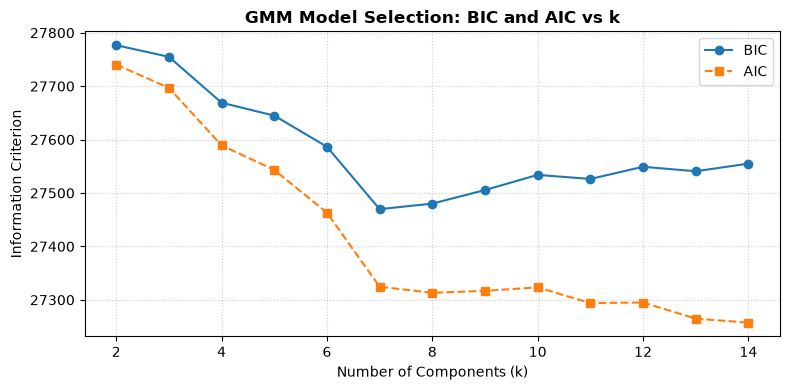

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(k_range, gmm_df["bics"], 'o-', label='BIC', color='tab:blue')
plt.plot(k_range, gmm_df["aics"], 's--', label='AIC', color='tab:orange')
plt.title('GMM Model Selection: BIC and AIC vs k', fontweight='bold')
plt.xlabel('Number of Components (k)')
plt.ylabel('Information Criterion')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

Using the elbow method select the number of clusters and print the mean and the variance of each cluster:

In [12]:
best_k = 7
gmm = GaussianMixture(n_components=best_k, covariance_type='full', n_init=10, random_state=random_state)

gmm.fit(X_transformed)
ypred_gmm = gmm.predict(X_transformed)

# Print Mean and Variance (Standard Deviation) for each cluster
print(f"GMM (k={best_k}) - Gaussian Parameters for E_sum:")
print("=" * 50)
means = gmm.means_.flatten()
stds = np.sqrt(gmm.covariances_.flatten())
weights = gmm.weights_.flatten()

df_gaussians = pd.DataFrame({
    'Cluster': range(best_k),
    'Weight (%)': weights * 100,
    'Mean (mu)': means,
    'Std (sigma)': stds
}).sort_values(by='Mean (mu)').reset_index(drop=True)

print(df_gaussians.to_string(index=False))

GMM (k=7) - Gaussian Parameters for E_sum:
 Cluster  Weight (%)  Mean (mu)  Std (sigma)
       3    6.774119  -1.701071     0.211291
       5   18.877128  -1.197521     0.153061
       1   10.493061  -0.678894     0.212214
       6   15.339774  -0.049583     0.184855
       2   17.533757   0.420384     0.185176
       4   20.046612   0.893774     0.189424
       0   10.935550   1.529437     0.252783


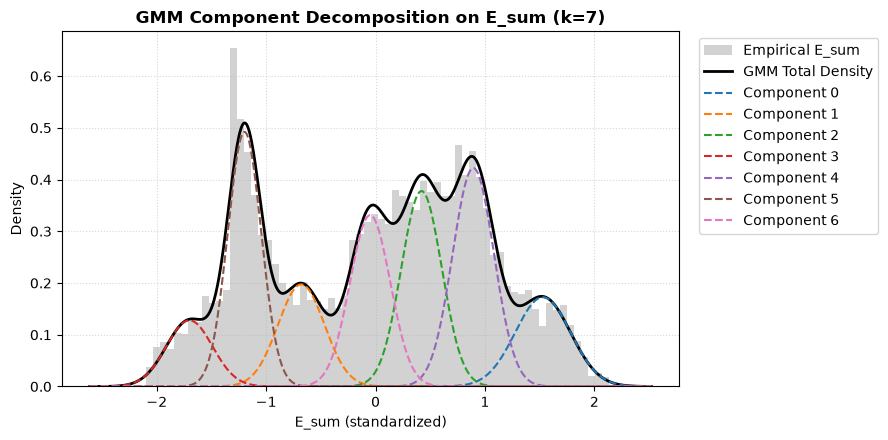

In [13]:
x_plot = pd.DataFrame(
    np.linspace(X_transformed["E_sum"].min(), X_transformed["E_sum"].max(), 1000),
    columns=["E_sum"],          # same column name used in gmm.fit
)
log_prob = gmm.score_samples(x_plot)
responsibilities = gmm.predict_proba(x_plot)

plt.figure(figsize=(9, 4.5))
# Real data distribution
plt.hist(X_transformed["E_sum"], bins=80, density=True, alpha=0.35, color='gray', label='Empirical E_sum')

# Full GMM mixture PDF
plt.plot(x_plot, np.exp(log_prob), 'k-', linewidth=2, label='GMM Total Density')

# Individual components
for i in range(best_k):
    comp_pdf = responsibilities[:, i] * np.exp(log_prob)
    plt.plot(x_plot, comp_pdf, '--', label=f'Component {i}')

plt.title(f'GMM Component Decomposition on E_sum (k={best_k})', fontweight='bold')
plt.xlabel('E_sum (standardized)')
plt.ylabel('Density')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

NMI Score: 0.2495
ARI Score: 0.1310


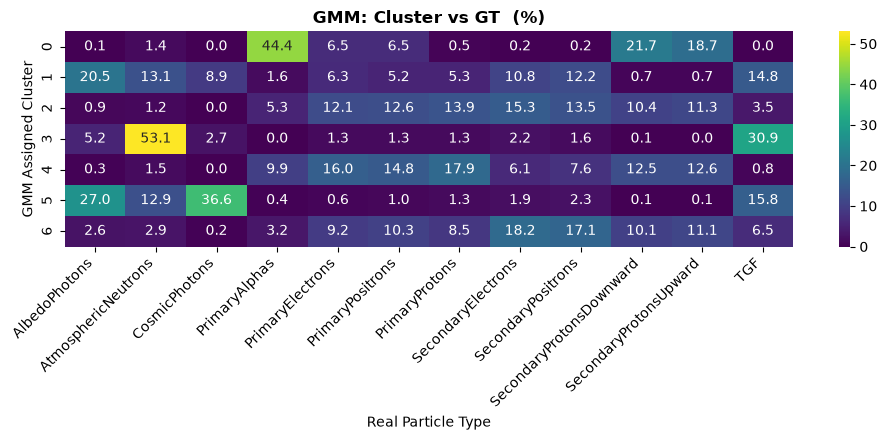

In [14]:
nmi = normalized_mutual_info_score(y, ypred_gmm)
ari = adjusted_rand_score(y, ypred_gmm)
print(f"NMI Score: {nmi:.4f}")
print(f"ARI Score: {ari:.4f}")

ct = pd.crosstab(ypred_gmm, y, normalize="index") * 100

plt.figure(figsize=(10, 4.5))
sns.heatmap(ct, annot=True, fmt=".1f", cmap="viridis")
plt.title(
    "GMM: Cluster vs GT  (%)",
    fontweight="bold",
)
plt.xlabel("Real Particle Type")
plt.ylabel("GMM Assigned Cluster")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 2 - Conclusions 

As we can see from the results, even a Mixture Models fail to effectively separate clusters. This is due to the presence only of the `E_sum` feature as only predictor. 

Sources: <br>

https://jakevdp.github.io/PythonDataScienceHandbook/05.12-gaussian-mixtures.html

https://scikit-learn.org/stable/modules/mixture.html

https://en.wikipedia.org/wiki/Mixture_model

https://scikit-learn.org/stable/modules/clustering.html#mutual-info-score

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html

https://en.wikipedia.org/wiki/Rand_index